In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from scipy.fft import fft, fftfreq
from scipy import signal
from os import listdir
from os.path import isfile, join
import re
import MasterPSD as PSD
from multiprocessing import Pool, cpu_count
from tqdm import tqdm
import VisAnalysis as Vis

In [2]:
NNF = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-26", subfolder="Night2LongNoFibre", verbose=True)
NF = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-26", subfolder="Night2Long", verbose=True)
MNF = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-26", subfolder="Medium2LongNoFibre", verbose=True)
MF = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-26", subfolder="Medium2Long", verbose=True)
DF = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-26", subfolder="Day2Long", verbose=True)
DNF = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-26", subfolder="Day2LongNoFibre", verbose=True)

Loaded 14 measurements from D:\PhD Thesis Writing\Data\2025-11-26\Night2LongNoFibre
Loaded 12 measurements from D:\PhD Thesis Writing\Data\2025-11-26\Night2Long
Loaded 12 measurements from D:\PhD Thesis Writing\Data\2025-11-26\Medium2LongNoFibre
Loaded 13 measurements from D:\PhD Thesis Writing\Data\2025-11-26\Medium2Long
Loaded 13 measurements from D:\PhD Thesis Writing\Data\2025-11-26\Day2Long
Loaded 12 measurements from D:\PhD Thesis Writing\Data\2025-11-26\Day2LongNoFibre


In [4]:
NL = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-28", subfolder="Night2Long", verbose=True)
NLF = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-28", subfolder="Night2LongFast", verbose=True)
NLVF = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-28", subfolder="Night2LongVeryFast", verbose=True)

Loaded 13 measurements from D:\PhD Thesis Writing\Data\2025-11-28\Night2Long
Loaded 13 measurements from D:\PhD Thesis Writing\Data\2025-11-28\Night2LongFast
Loaded 13 measurements from D:\PhD Thesis Writing\Data\2025-11-28\Night2LongVeryFast


In [7]:
for i in range(len(DNF)):
    print(i,DNF[i]['name'])

0 Day_2_1MhzGate_107uWperArm_Rmp1000Hz_voaramp
1 Day_2_1MhzGate_107uWperArm_Rmp100Hz_voaramp
2 Day_2_1MhzGate_107uWperArm_Rmp10Hz_voaramp
3 Day_2_1MhzGate_107uWperArm_Rmp1Hz_voaramp
4 Day_2_1MhzGate_107uWperArm_Rmp1000Hz_nomodulation
5 Day_2_1MhzGate_107uWperArm_Rmp100Hz_nomodulation
6 Day_2_1MhzGate_107uWperArm_Rmp10Hz_nomodulation
7 Day_2_1MhzGate_107uWperArm_Rmp1Hz_nomodulation
8 Day_2_1MhzGate_107uWperArm_Rmp1000Hz
9 Day_2_1MhzGate_107uWperArm_Rmp100Hz
10 Day_2_1MhzGate_107uWperArm_Rmp10Hz
11 Day_2_1MhzGate_107uWperArm_Rmp1Hz


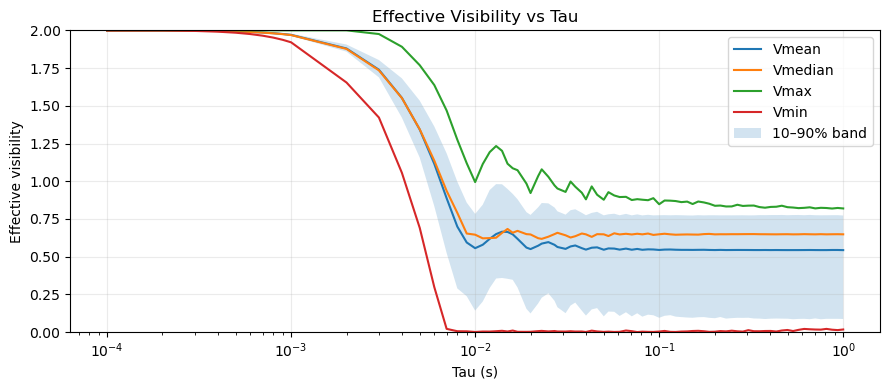

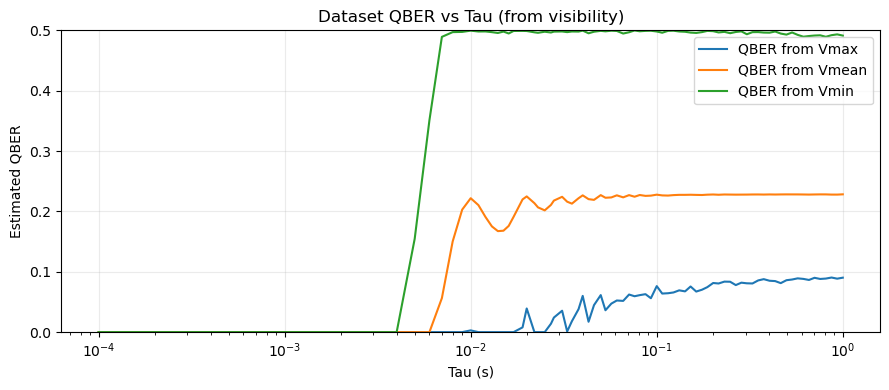

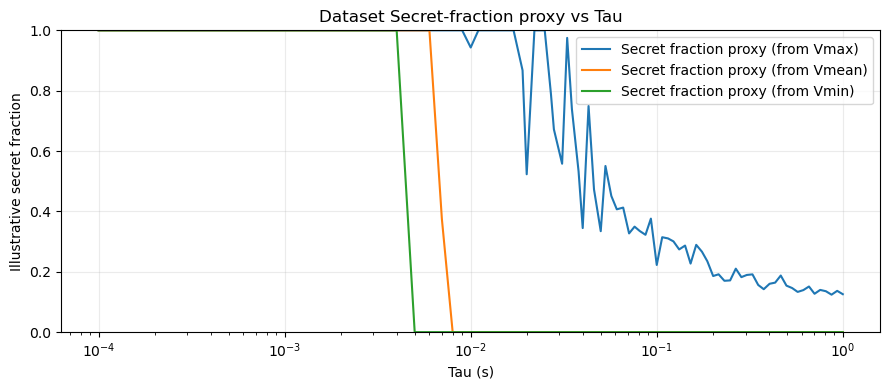

Operating tau (s): 0.01
Knee tau mean (s): nan
Knee tau median (s): nan


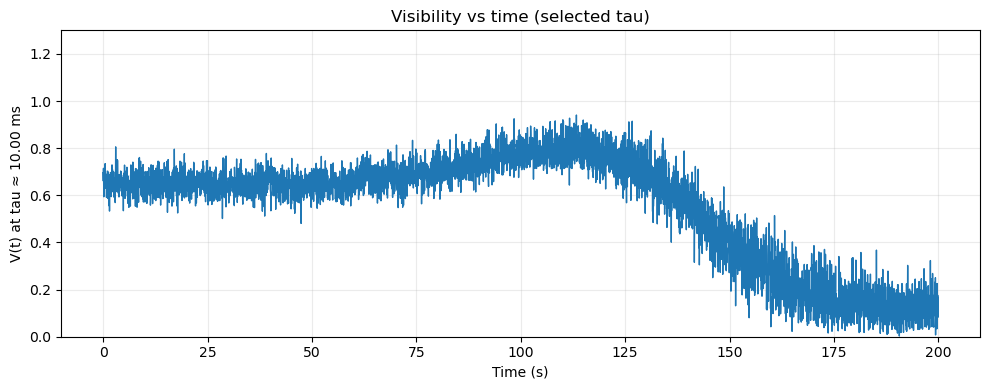

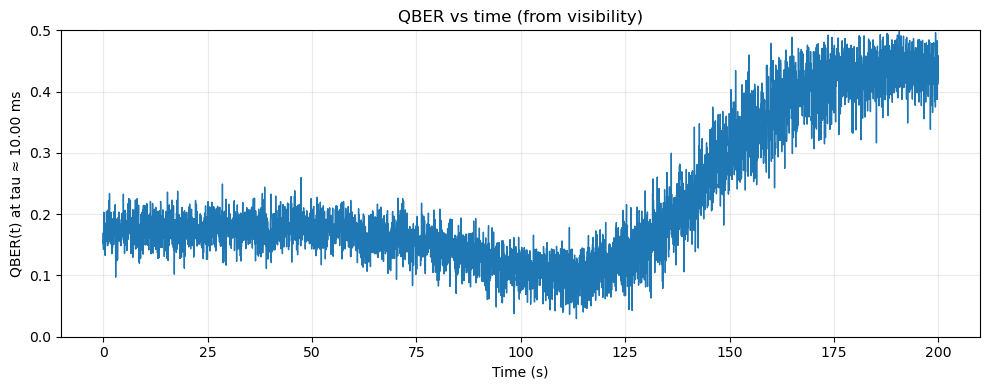

[Selected tau diagnostics]
{'dt': 0.0001, 'K': 100, 'S': 50, 'tau': 0.01, 'step': 0.005, 'n_windows_total': 39999, 'n_windows_used': 39999, 'mean_counts_per_window_used': 219.6673666841671}
V median: 0.6457464100836195
V mean:   0.5562867580111673
V 10–90%: 0.14252919810481107 … 0.7834428348088744


In [9]:
DNF_100_voa=Vis.AnalyseMeasurement_New(DNF,1,100,100,1e-4,1,0.01,10)

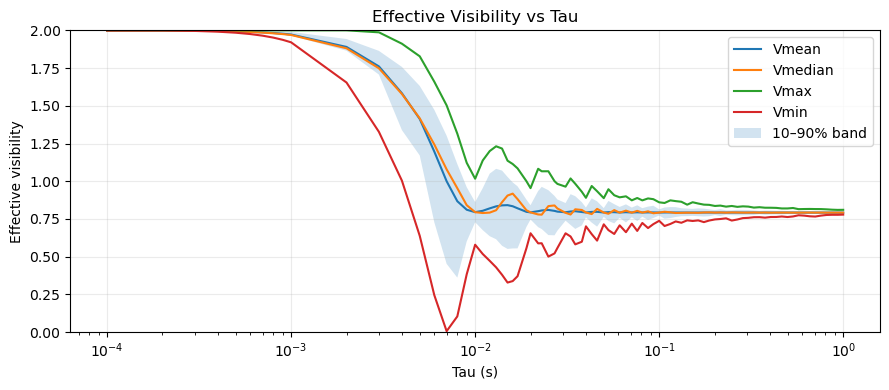

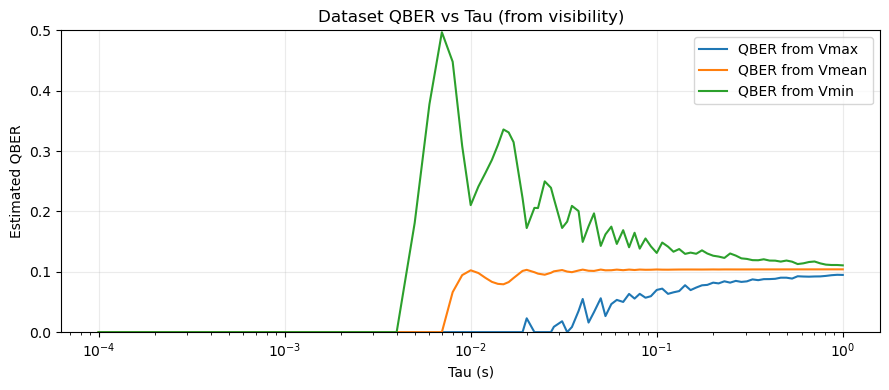

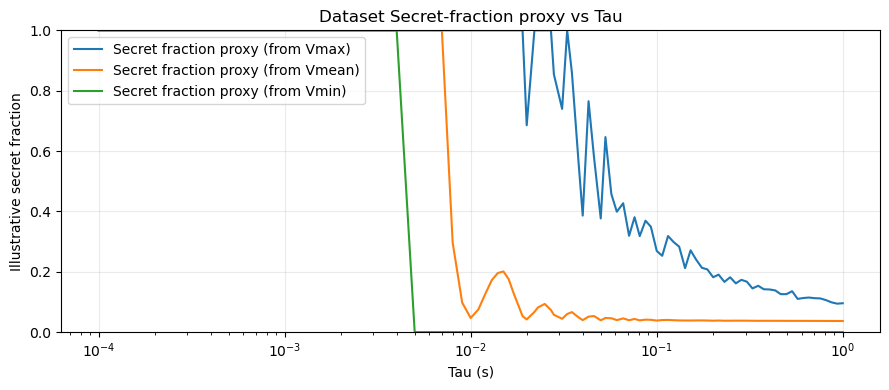

Operating tau (s): 0.01
Knee tau mean (s): nan
Knee tau median (s): nan


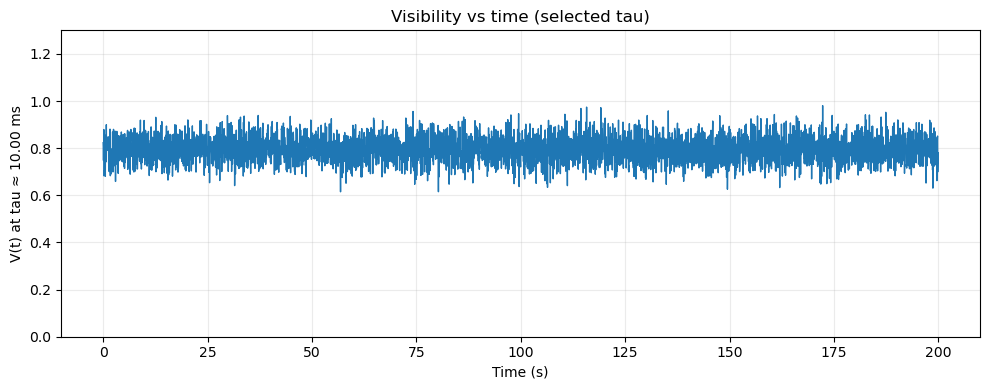

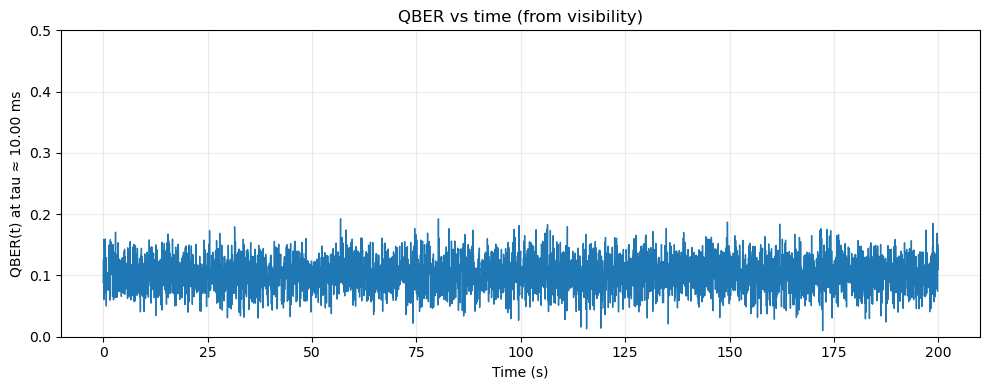

[Selected tau diagnostics]
{'dt': 0.0001, 'K': 100, 'S': 50, 'tau': 0.01, 'step': 0.005, 'n_windows_total': 39999, 'n_windows_used': 39999, 'mean_counts_per_window_used': 220.38603465086626}
V median: 0.7949548849167506
V mean:   0.7951547106056348
V 10–90%: 0.7283649595712579 … 0.86195649986668


In [11]:
DNF_100_nm=Vis.AnalyseMeasurement_New(DNF,5,100,100,1e-4,1,0.01,10)

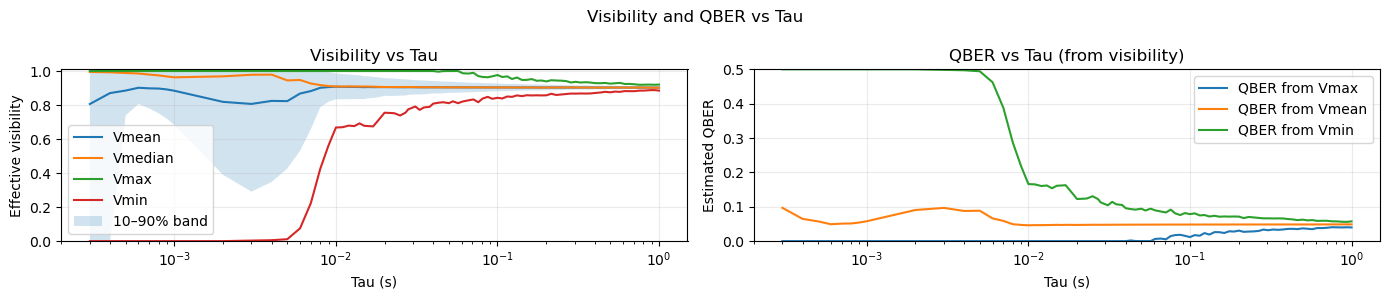

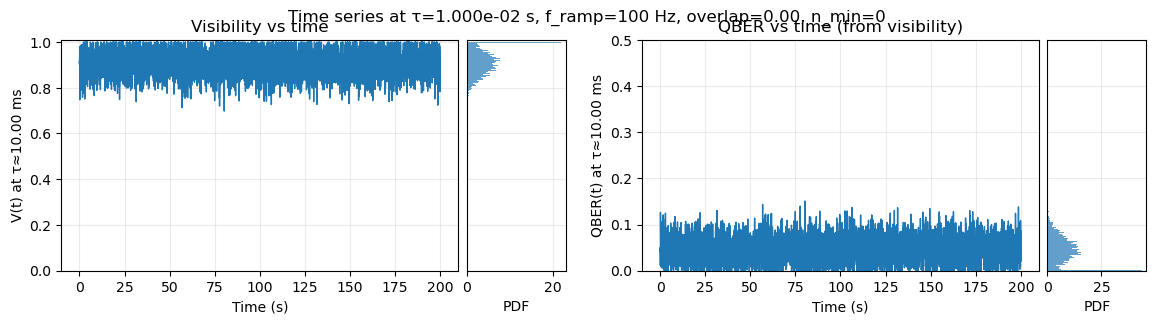

[Selected tau diagnostics]
{'dt': 0.0001, 'K_samples': 100, 'S_samples': 100, 'tau_eff_s': 0.01, 'step_eff_s': 0.01, 'n_windows_total': 20000, 'n_windows_used': 20000, 'n_phase': 64, 'iters_ab': 8, 'lam_floor': 1e-06, 'n_min_counts': 0.0, 'clip_for_qber': False}
V median: 0.9088076587112511
V mean:   0.9072207617958328
V 10–90%: 0.8336009674672773 … 0.9845218689388061


In [5]:
DNF_100_nm2=Vis.AnalyseMeasurement_NewNumba(DNF,5,100,100,1e-4,1,0.01,10,overlap=0,hist_bins=100)

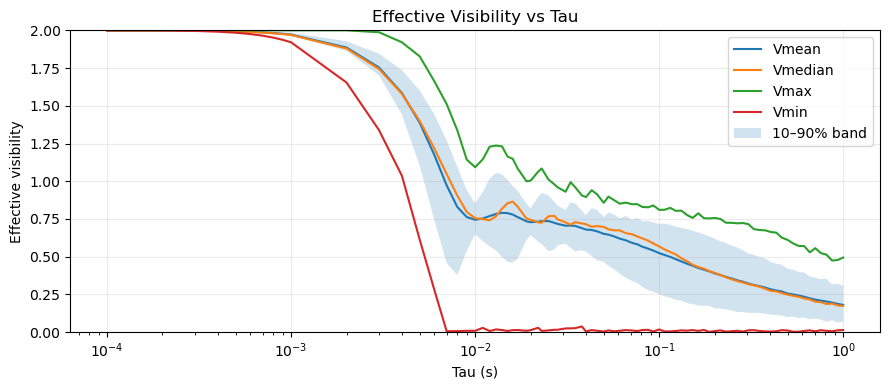

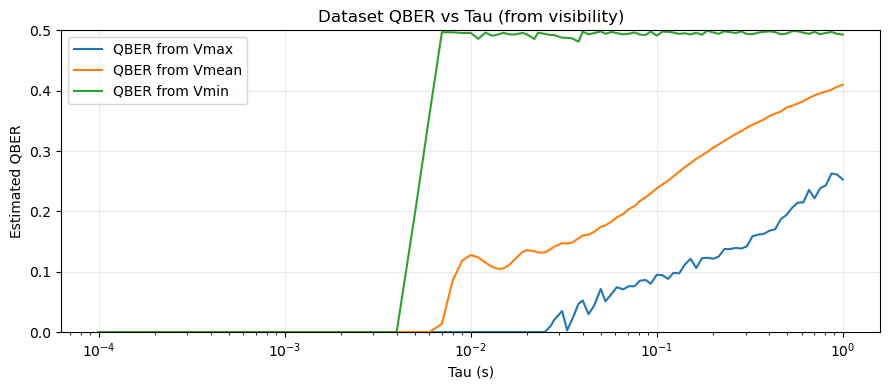

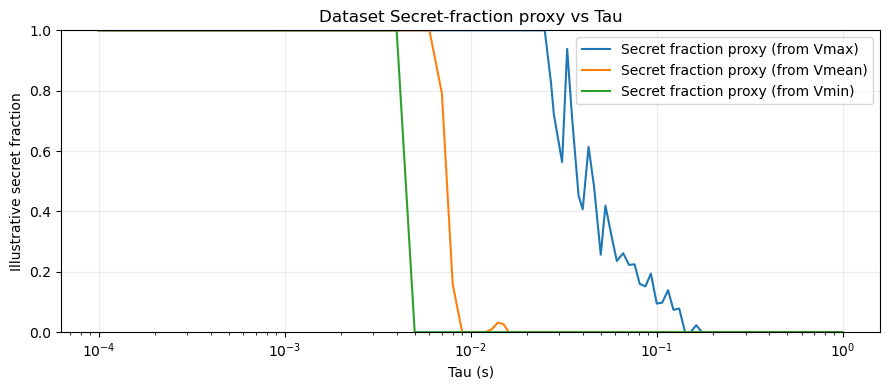

Operating tau (s): 0.01
Knee tau mean (s): 0.123
Knee tau median (s): 0.115


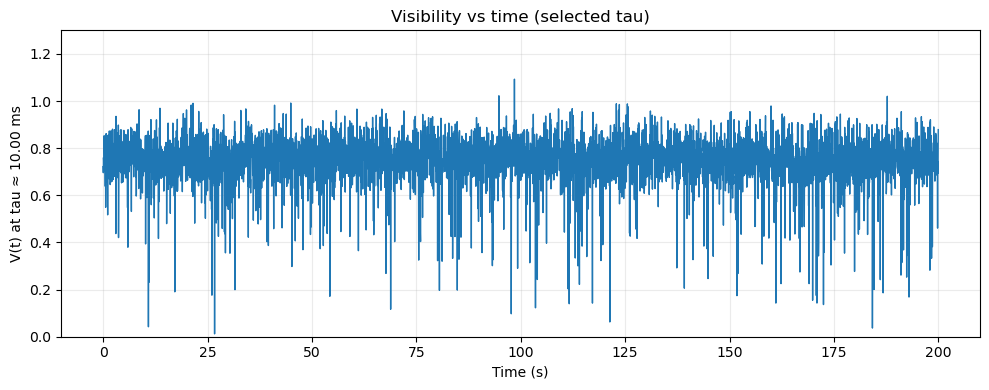

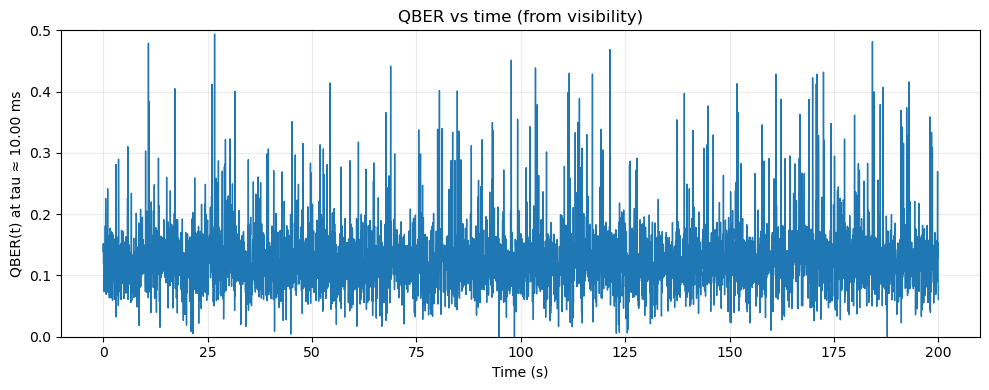

[Selected tau diagnostics]
{'dt': 0.0001, 'K': 100, 'S': 50, 'tau': 0.01, 'step': 0.005, 'n_windows_total': 39999, 'n_windows_used': 39999, 'mean_counts_per_window_used': 222.43483587089676}
V median: 0.7553179344453346
V mean:   0.7445774146135046
V 10–90%: 0.6481592690327133 … 0.8529459087624882


In [12]:
DNF_100_em=Vis.AnalyseMeasurement_New(DNF,9,100,100,1e-4,1,0.01,10)

C:\Users\Ry\VisAnalysis.py:2359: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


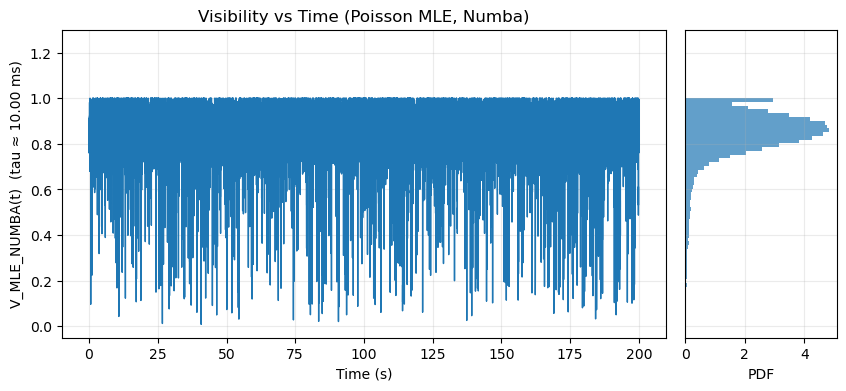

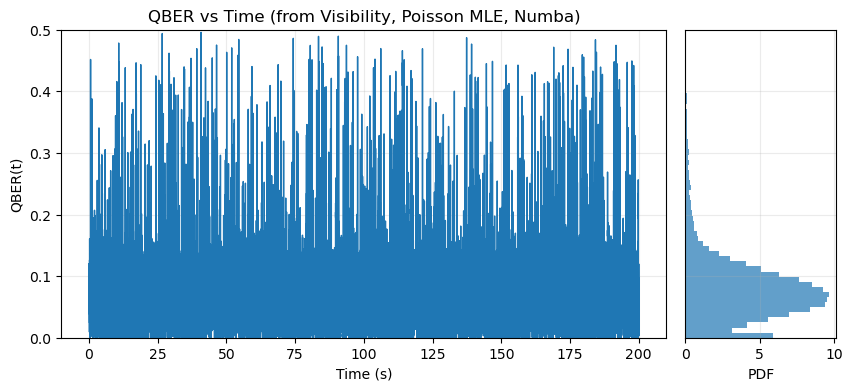

In [7]:
tcent, Vt, QBERir, diag = Vis.lockin_visibility_vs_time_mle_numba(
        DNF[9]['data']['timestamps'], DNF[9]['data']['counts'], f_ramp=100, tau=0.01, step=None,
        n_min=0, clip=False,make_plots = True, verbose=False, n_phase = 64,iters_ab = 8,
    lam_floor = 1e-6)

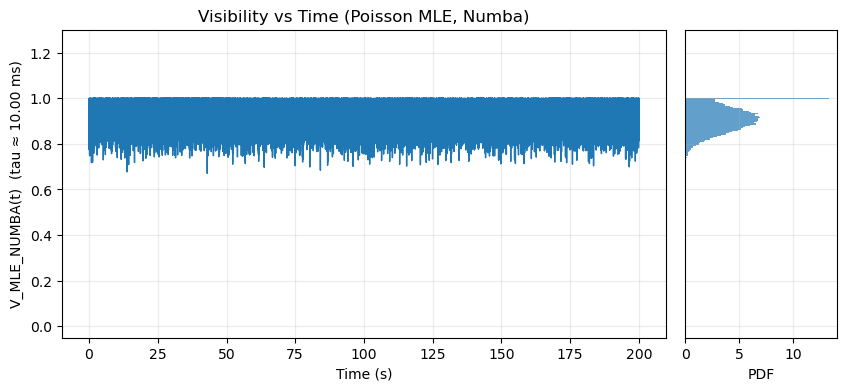

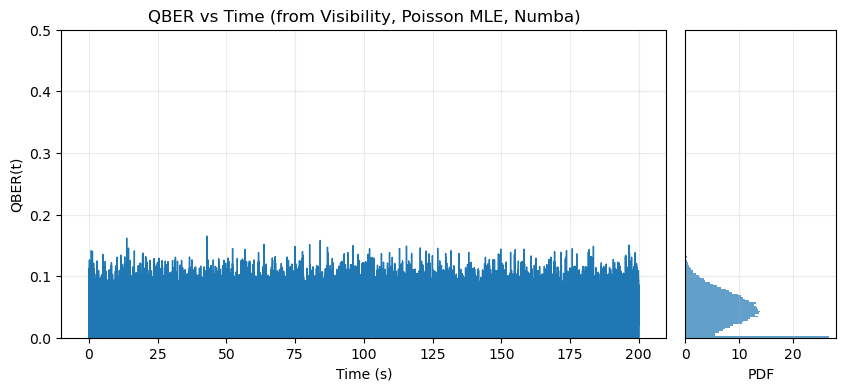

In [9]:
tcent2, Vt2, QBERir2, diag2 = Vis.lockin_visibility_vs_time_mle_numba(
        DNF[5]['data']['timestamps'], DNF[5]['data']['counts'], f_ramp=100, tau=0.01, step=None,
        n_min=0, clip=False,make_plots = True, verbose=False, n_phase = 64,iters_ab = 8,
    lam_floor = 1e-6)

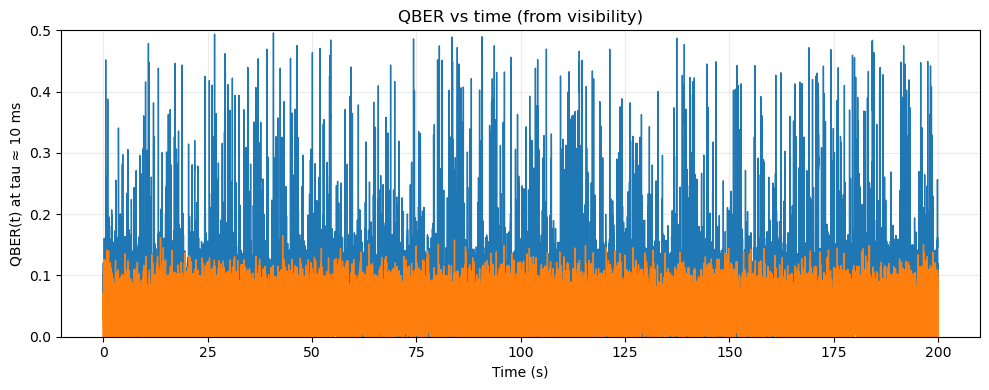

In [11]:
plt.figure(figsize=(10, 4))
plt.plot(tcent, QBERir, linewidth=1)
plt.plot(tcent2, QBERir2, linewidth=1)
plt.ylim(0, 0.5)
plt.xlabel("Time (s)")
plt.ylabel(f"QBER(t) at tau ≈ 10 ms")
plt.title("QBER vs time (from visibility)")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

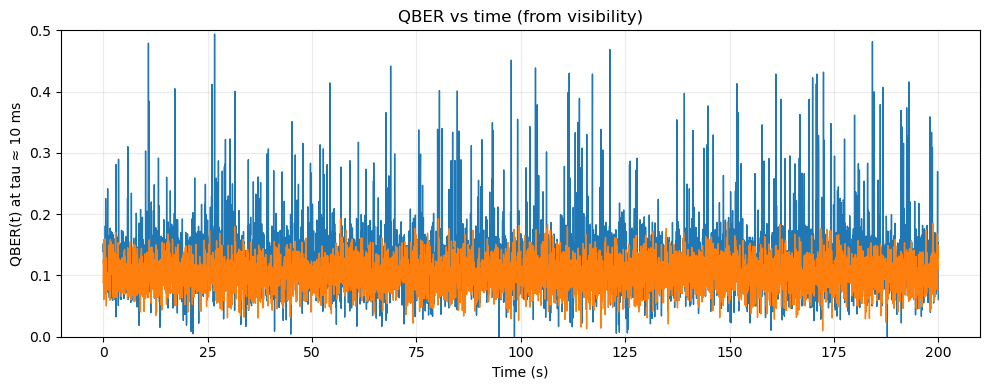

In [14]:
plt.figure(figsize=(10, 4))
plt.plot(DNF_100_em[0][2][0], DNF_100_em[0][2][1], linewidth=1)
plt.plot(DNF_100_nm[0][2][0], DNF_100_nm[0][2][1], linewidth=1)
plt.ylim(0, 0.5)
plt.xlabel("Time (s)")
plt.ylabel(f"QBER(t) at tau ≈ 10 ms")
plt.title("QBER vs time (from visibility)")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

In [21]:
np.save('DNF_100_em.npy',DNF_100_em[0][2])
np.save('DNF_100_nm.npy',DNF_100_nm[0][2])
np.save('DNF_100_voa.npy',DNF_100_voa[0][2])

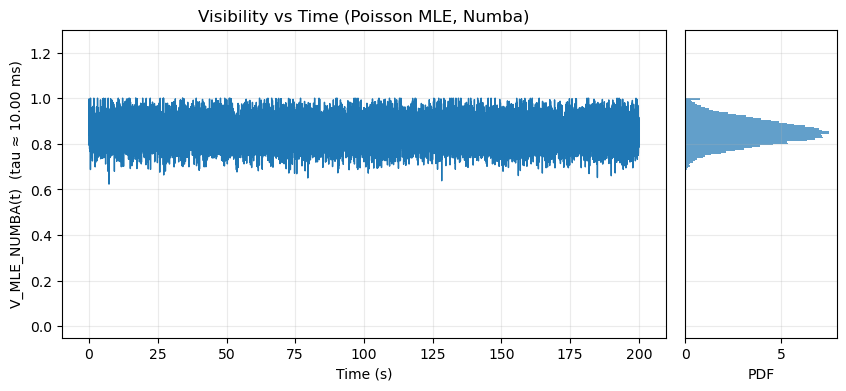

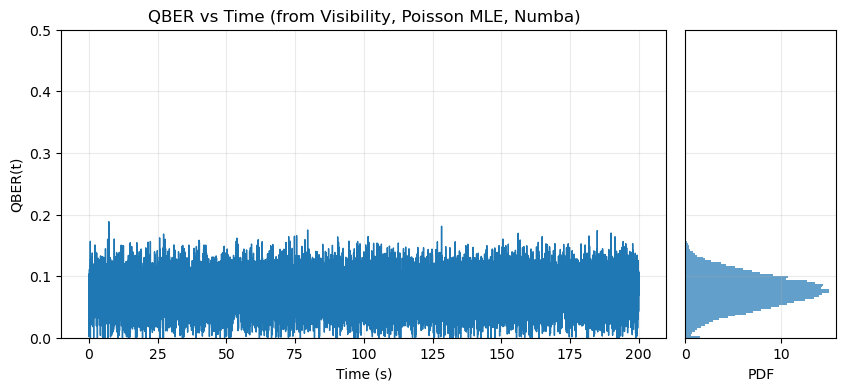

In [33]:
tcent3, Vt3, QBERir3, diag3=Vis.lockin_visibility_vs_time_mle_numba(
        MNF[5]['data']['timestamps'], MNF[5]['data']['counts'], f_ramp=100, tau=0.01, step=None,
        n_min=0, clip=False,make_plots = True, verbose=False, n_phase = 64,iters_ab = 8,
    lam_floor = 1e-6)

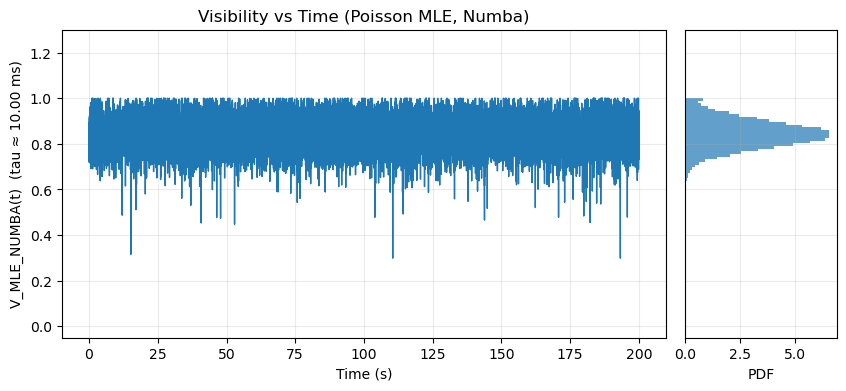

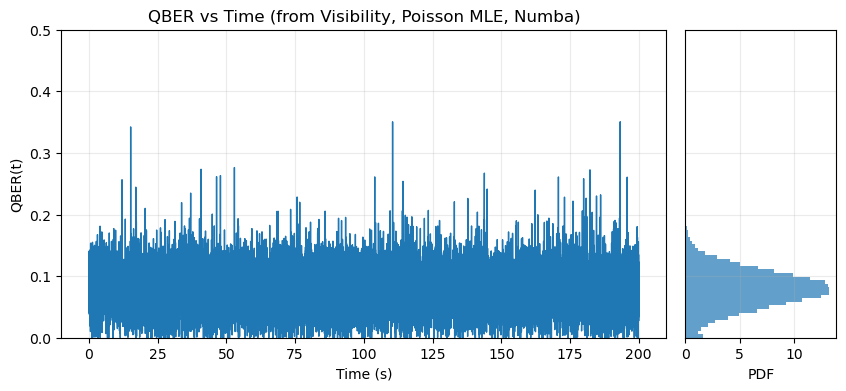

In [34]:
tcent4, Vt4, QBERir4, diag4=Vis.lockin_visibility_vs_time_mle_numba(
        MNF[9]['data']['timestamps'], MNF[9]['data']['counts'], f_ramp=100, tau=0.01, step=None,
        n_min=0, clip=False,make_plots = True, verbose=False, n_phase = 64,iters_ab = 8,
    lam_floor = 1e-6)

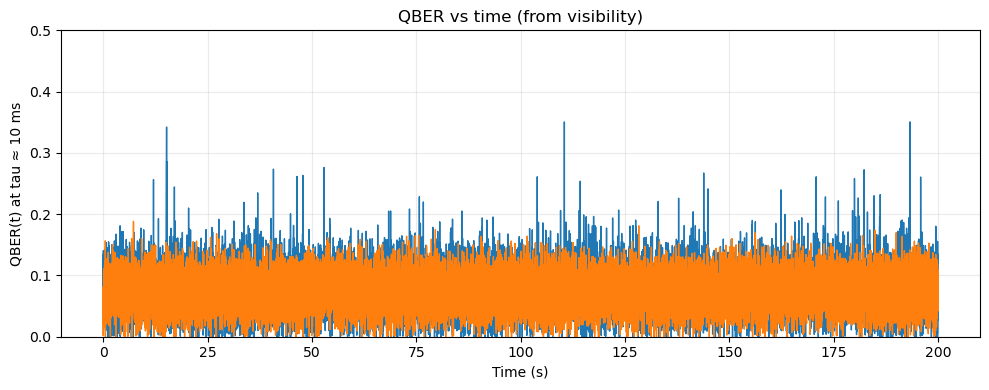

In [41]:
plt.figure(figsize=(10, 4))
plt.plot(tcent4, QBERir4, linewidth=1)
plt.plot(tcent3, QBERir3, linewidth=1)
plt.ylim(0, 0.5)
plt.xlabel("Time (s)")
plt.ylabel(f"QBER(t) at tau ≈ 10 ms")
plt.title("QBER vs time (from visibility)")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

In [43]:
for i in range(len(MNF)):
    print(i,NNF[i]['name'])

0 Night_2_1MhzGate_195uWperArm_Rmp1000Hz_voaramp
1 Night_2_1MhzGate_195uWperArm_Rmp100Hz_voaramp
2 Night_2_1MhzGate_195uWperArm_Rmp10Hz_voaramp
3 Night_2_1MhzGate_195uWperArm_Rmp1Hz_voaramp
4 Night_2_1MhzGate_195uWperArm_Rmp1000Hz_nomodulation
5 Night_2_1MhzGate_195uWperArm_Rmp100Hz_nomodulation
6 Night_2_1MhzGate_195uWperArm_Rmp10Hz_nomodulation
7 Night_2_1MhzGate_195uWperArm_Rmp1Hz_nomodulation
8 Night_2_1MhzGate_195uWperArm_Rmp1000Hz
9 Night_2_1MhzGate_195uWperArm_Rmp100Hz
10 Night_2_1MhzGate_195uWperArm_Rmp10Hz
11 Night_2_1MhzGate_195uWperArm_Rmp1Hz


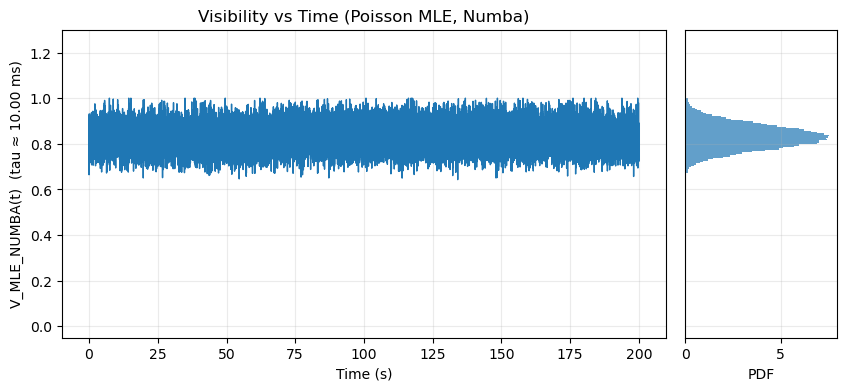

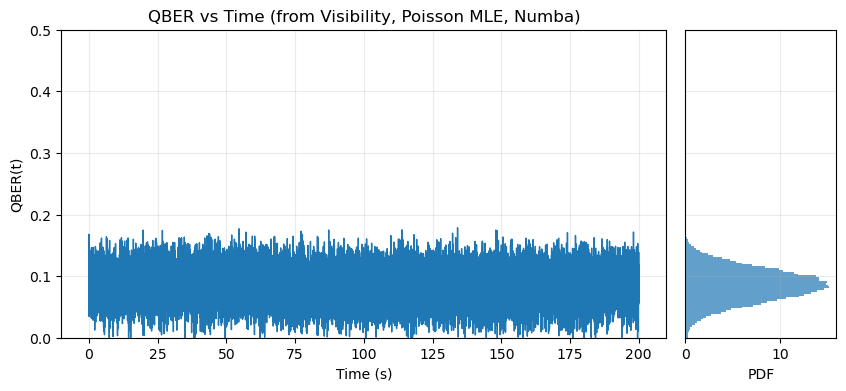

In [45]:
tcent6, Vt6, QBERir6, diag6=Vis.lockin_visibility_vs_time_mle_numba(
        NNF[5]['data']['timestamps'],NNF[5]['data']['counts'], f_ramp=100, tau=0.01, step=None,
        n_min=0, clip=False,make_plots = True, verbose=False, n_phase = 64,iters_ab = 8,
    lam_floor = 1e-6)

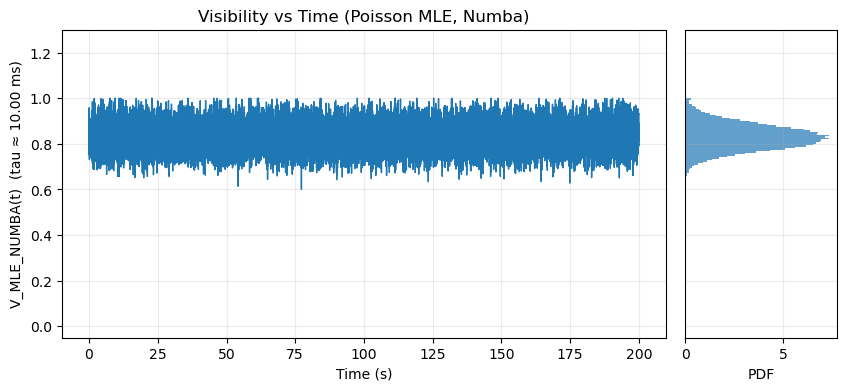

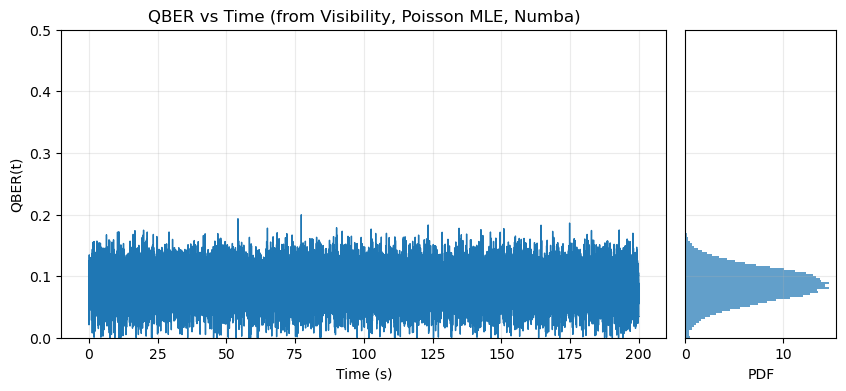

In [46]:
tcent5, Vt5, QBERir5, diag5=Vis.lockin_visibility_vs_time_mle_numba(
        NNF[9]['data']['timestamps'], NNF[9]['data']['counts'], f_ramp=100, tau=0.01, step=None,
        n_min=0, clip=False,make_plots = True, verbose=False, n_phase = 64,iters_ab = 8,
    lam_floor = 1e-6)

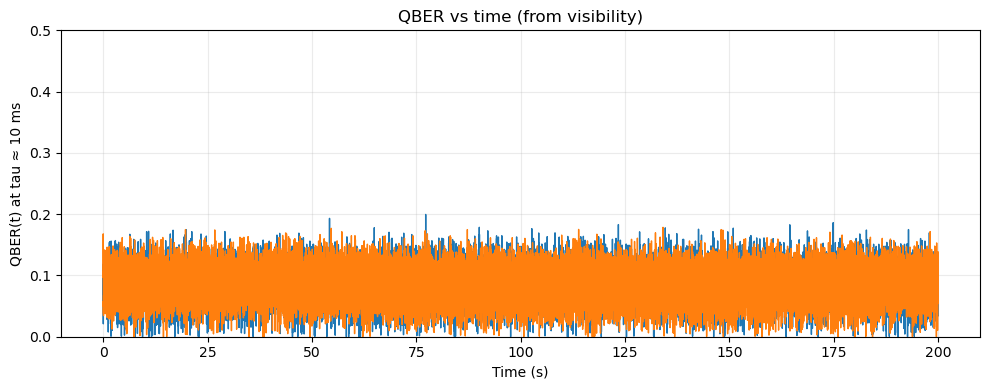

In [49]:
plt.figure(figsize=(10, 4))
plt.plot(tcent5, QBERir5, linewidth=1)
plt.plot(tcent6, QBERir6, linewidth=1)
plt.ylim(0, 0.5)
plt.xlabel("Time (s)")
plt.ylabel(f"QBER(t) at tau ≈ 10 ms")
plt.title("QBER vs time (from visibility)")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

In [54]:
for i in range(len(DNF)):
    print(i,DNF[i]['name'])

0 Day_2_1MhzGate_107uWperArm_Rmp1000Hz_voaramp
1 Day_2_1MhzGate_107uWperArm_Rmp100Hz_voaramp
2 Day_2_1MhzGate_107uWperArm_Rmp10Hz_voaramp
3 Day_2_1MhzGate_107uWperArm_Rmp1Hz_voaramp
4 Day_2_1MhzGate_107uWperArm_Rmp1000Hz_nomodulation
5 Day_2_1MhzGate_107uWperArm_Rmp100Hz_nomodulation
6 Day_2_1MhzGate_107uWperArm_Rmp10Hz_nomodulation
7 Day_2_1MhzGate_107uWperArm_Rmp1Hz_nomodulation
8 Day_2_1MhzGate_107uWperArm_Rmp1000Hz
9 Day_2_1MhzGate_107uWperArm_Rmp100Hz
10 Day_2_1MhzGate_107uWperArm_Rmp10Hz
11 Day_2_1MhzGate_107uWperArm_Rmp1Hz


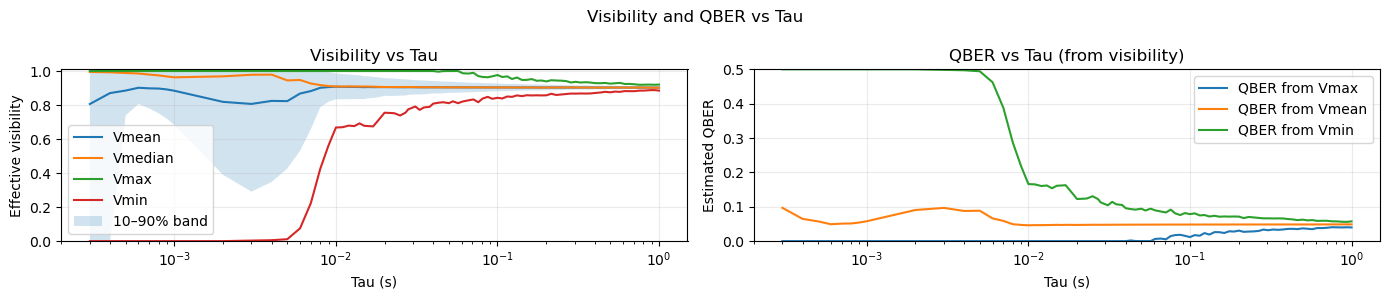

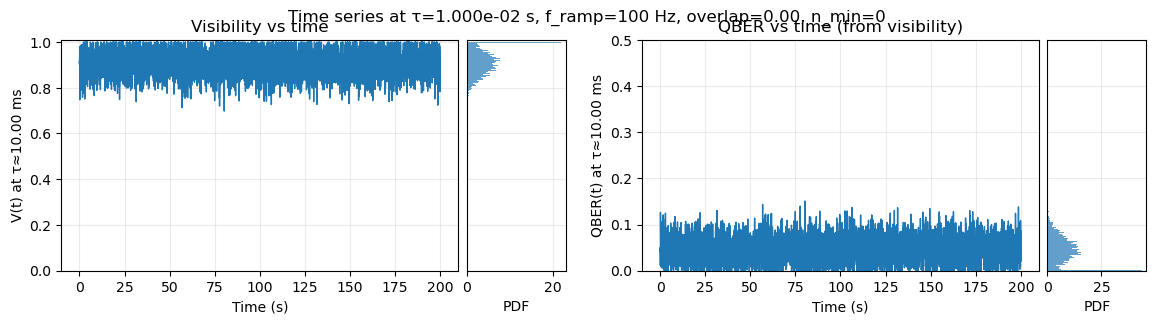

[Selected tau diagnostics]
{'dt': 0.0001, 'K_samples': 100, 'S_samples': 100, 'tau_eff_s': 0.01, 'step_eff_s': 0.01, 'n_windows_total': 20000, 'n_windows_used': 20000, 'n_phase': 64, 'iters_ab': 8, 'lam_floor': 1e-06, 'n_min_counts': 0.0, 'clip_for_qber': False}
V median: 0.9088076587112511
V mean:   0.9072207617958328
V 10–90%: 0.8336009674672773 … 0.9845218689388061


In [53]:
DNF_100_nm2=Vis.AnalyseMeasurement_NewNumba(DNF,5,100,100,1e-4,1,0.01,10,overlap=0,hist_bins=100)

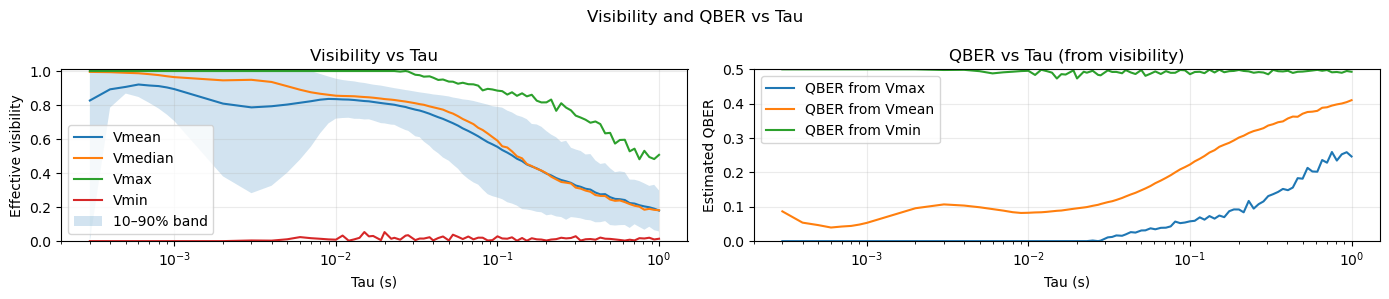

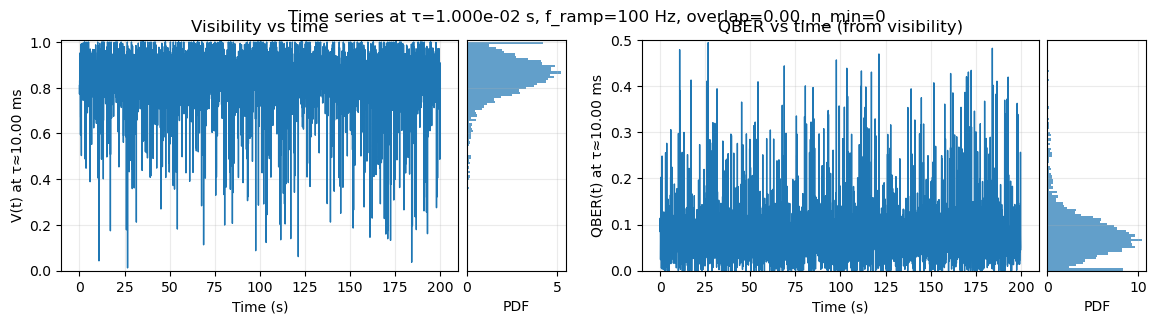

[Selected tau diagnostics]
{'dt': 0.0001, 'K_samples': 100, 'S_samples': 100, 'tau_eff_s': 0.01, 'step_eff_s': 0.01, 'n_windows_total': 20000, 'n_windows_used': 20000, 'n_phase': 64, 'iters_ab': 8, 'lam_floor': 1e-06, 'n_min_counts': 0.0, 'clip_for_qber': False}
V median: 0.8543960211953734
V mean:   0.8344718016608497
V 10–90%: 0.7198291478609508 … 0.9542216654906063


In [55]:
DNF_100_em2=Vis.AnalyseMeasurement_NewNumba(DNF,9,100,100,1e-4,1,0.01,10,overlap=0,hist_bins=100)

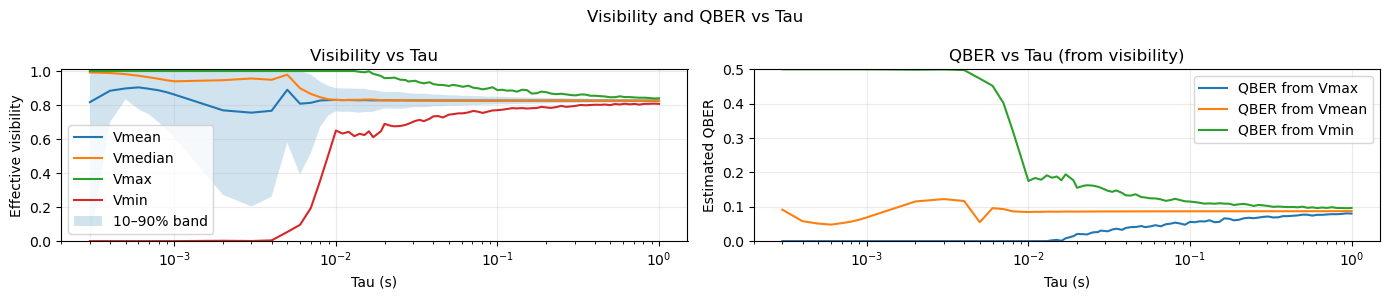

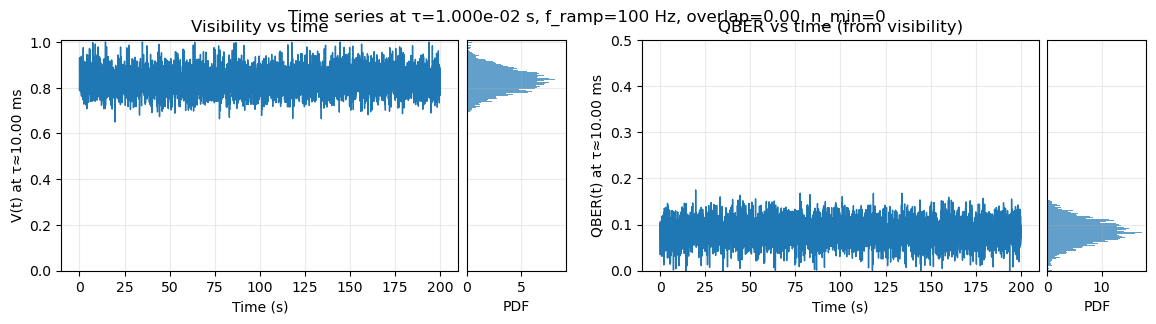

[Selected tau diagnostics]
{'dt': 0.0001, 'K_samples': 100, 'S_samples': 100, 'tau_eff_s': 0.01, 'step_eff_s': 0.01, 'n_windows_total': 20000, 'n_windows_used': 20000, 'n_phase': 64, 'iters_ab': 8, 'lam_floor': 1e-06, 'n_min_counts': 0.0, 'clip_for_qber': False}
V median: 0.8293548460212062
V mean:   0.8298888649300801
V 10–90%: 0.763055657152869 … 0.8981100404394023


In [56]:
NNF_100_nm2=Vis.AnalyseMeasurement_NewNumba(NNF,5,100,100,1e-4,1,0.01,10,overlap=0,hist_bins=100)

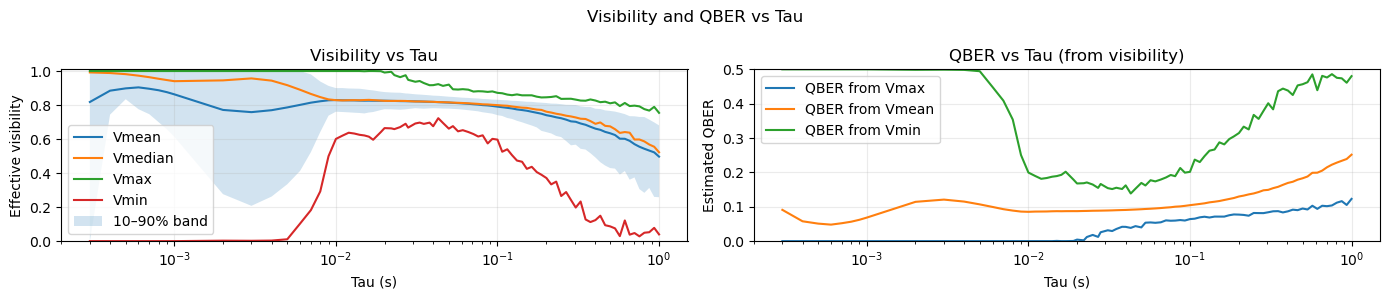

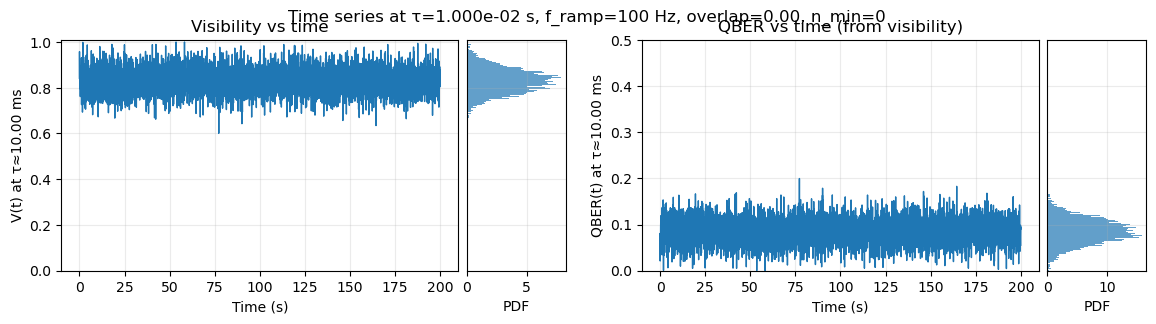

[Selected tau diagnostics]
{'dt': 0.0001, 'K_samples': 100, 'S_samples': 100, 'tau_eff_s': 0.01, 'step_eff_s': 0.01, 'n_windows_total': 20000, 'n_windows_used': 20000, 'n_phase': 64, 'iters_ab': 8, 'lam_floor': 1e-06, 'n_min_counts': 0.0, 'clip_for_qber': False}
V median: 0.8280973746935052
V mean:   0.8288156294559805
V 10–90%: 0.76028701923666 … 0.8989724659662629


In [57]:
NNF_100_em2=Vis.AnalyseMeasurement_NewNumba(NNF,9,100,100,1e-4,1,0.01,10,overlap=0,hist_bins=100)

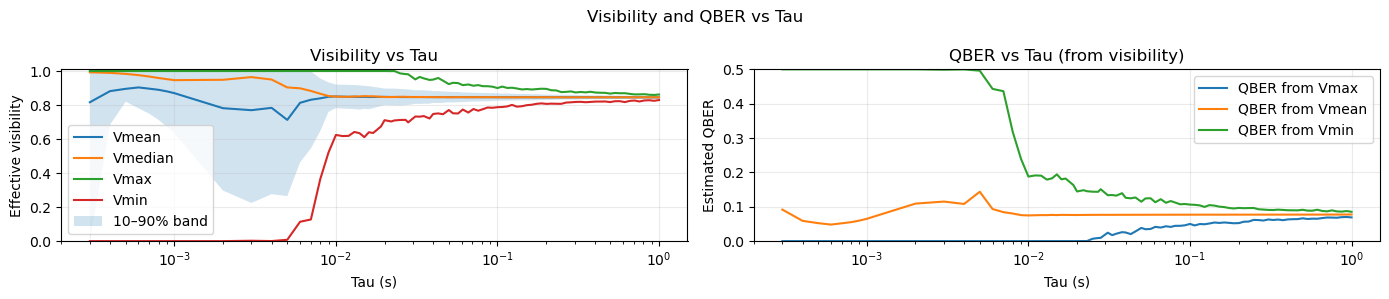

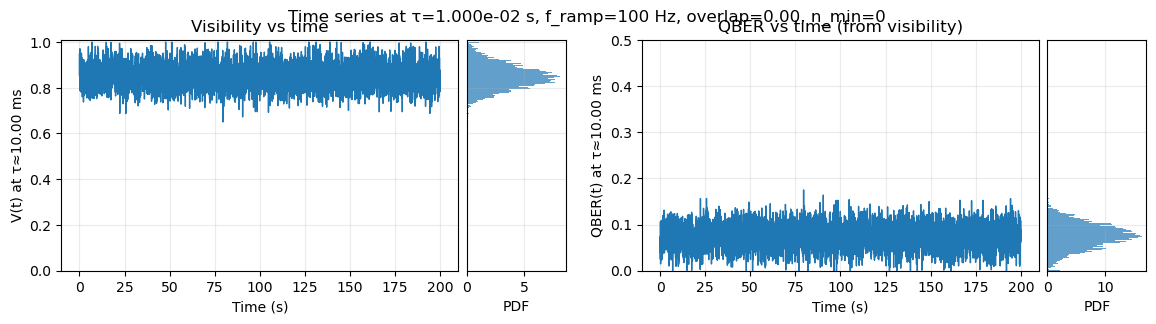

[Selected tau diagnostics]
{'dt': 0.0001, 'K_samples': 100, 'S_samples': 100, 'tau_eff_s': 0.01, 'step_eff_s': 0.01, 'n_windows_total': 20000, 'n_windows_used': 20000, 'n_phase': 64, 'iters_ab': 8, 'lam_floor': 1e-06, 'n_min_counts': 0.0, 'clip_for_qber': False}
V median: 0.8491453274969928
V mean:   0.8499036560454472
V 10–90%: 0.7812491248877713 … 0.9202294992486624


In [58]:
MNF_100_nm2=Vis.AnalyseMeasurement_NewNumba(MNF,5,100,100,1e-4,1,0.01,10,overlap=0,hist_bins=100)

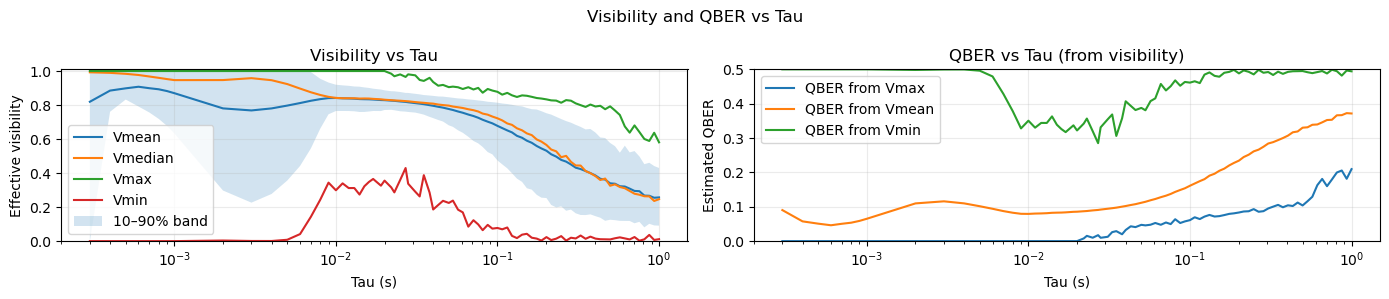

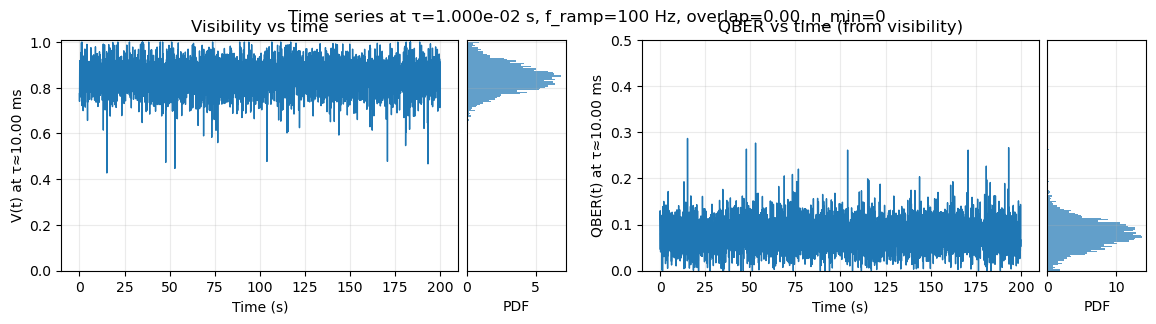

[Selected tau diagnostics]
{'dt': 0.0001, 'K_samples': 100, 'S_samples': 100, 'tau_eff_s': 0.01, 'step_eff_s': 0.01, 'n_windows_total': 20000, 'n_windows_used': 20000, 'n_phase': 64, 'iters_ab': 8, 'lam_floor': 1e-06, 'n_min_counts': 0.0, 'clip_for_qber': False}
V median: 0.8413227832410048
V mean:   0.8409450222267726
V 10–90%: 0.7640888030007157 … 0.9189007523854286


In [59]:
MNF_100_em2=Vis.AnalyseMeasurement_NewNumba(MNF,9,100,100,1e-4,1,0.01,10,overlap=0,hist_bins=100)

In [62]:
np.save('MNF_100_em_Numba.npy', np.array(MNF_100_em2, dtype=object), allow_pickle=True)
np.save('MNF_100_nm_Numba.npy', np.array(MNF_100_nm2, dtype=object), allow_pickle=True)

In [60]:
np.save('DNF_100_em_Numba.npy', np.array(DNF_100_em2, dtype=object), allow_pickle=True)
np.save('DNF_100_nm_Numba.npy', np.array(DNF_100_nm2, dtype=object), allow_pickle=True)

In [61]:
np.save('NNF_100_em_Numba.npy', np.array(NNF_100_em2, dtype=object), allow_pickle=True)
np.save('NNF_100_nm_Numba.npy', np.array(NNF_100_nm2, dtype=object), allow_pickle=True)